# 02 Estimate: baselines and SARIMA models in the backtest

A forecasting model is only worth using if it beats the simple rules a planner could apply without any model, such as repeating the same month of last year or taking the average of the last twelve months. So before we trust any model, we need these simple rules, called baselines, and a fair test on the past, the backtest: we go back in time, forecast month after month using only the data known then, and compare each forecast with what really happened. This notebook sets up both, and runs three simple rules and three (S)ARIMA models, classic models for time series, through the backtest.

We build the forecasts in four steps, each adding one thing to the step before, so that we can see what each addition is worth:

| Step | Notebook | Models | What is new compared with the step before |
|---|---|---|---|
| 1. Forecasts to beat | **02 (this one)** | seasonal naive, 12-month average, random walk | nothing is estimated: simple rules any planner could use |
| 2. A classic time-series model | **02 (this one)** | three (S)ARIMA models | a model estimated from the series' own past |
| 3. A regression we can explain | `02b` | linear regression, Ridge, Lasso | we choose the inputs ourselves and can read what the model learns |
| 4. Information from outside Switzerland | `02c` | the same regressions + two route features | Frontex detections on the routes to Switzerland: do they announce changes earlier? |

Steps 1 and 2 share this notebook because both use only the series itself, with no features to build. All four steps use exactly the same backtest, and this is also the order in which `03_evaluate.ipynb` compares the models. In our project plan, a SARIMA model was one of the baselines; why we changed the main comparison is explained at the start of `03_evaluate.ipynb`.

We read the clean series from `01_preprocess.ipynb` (`../data/processed/asylum_clean.csv`). We save all forecasts in `../data/processed/backtest_forecasts.csv`, with one row per model, forecast month and horizon, and one figure in `../output/figures/`. Here we only produce forecasts; how good they are is measured in `03_evaluate.ipynb`. The test period (October 2024 to September 2026) is **not used** in this notebook, so that it stays a fair check at the very end.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.arima.model import ARIMA

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the clean data

We load the clean series saved by `01_preprocess.ipynb`. For each month it has the number of applications, its logarithm and a label for the part of the data the month belongs to:

| Label | Months | Number | Used for |
|---|---|---|---|
| `training` | 2008-01 to 2012-12 | 60 | the first training window only |
| `backtest` | 2013-01 to 2024-09 | 141 | comparing and choosing models (02, 02b, 02c, 03) |
| `test` | 2024-10 to 2026-09 | 24 | the final check, once, in `04_test.ipynb` |

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")

y = clean["applicants_total"].to_numpy(dtype=float)     # applications in persons
log_y = clean["log_applicants"].to_numpy(dtype=float)   # log of applications
months = clean.index

print(clean["period"].value_counts())

period
backtest    141
training     60
test         24
Name: count, dtype: int64


## 2. What do we know at the moment of the forecast?

A backtest is only honest if each forecast uses exactly the information a planner would have had at that moment. So we fix three things first: **when** we forecast, **how far ahead**, and **on which months** the models learn.

**When: the cutoff.** SEM publishes the number of applications for a month around the 15th of the following month. Our data come from Eurostat, which publishes later, but its totals equal SEM's up to rounding (see `data/raw/SOURCES.md`), so we use SEM's timing. Around the 15th of month $m$, the newest known month is $m-1$. We call it the **forecast origin** $t$. A forecast of month $t+h$ made at origin $t$, written $\hat y_{t+h \mid t}$, uses only months up to $t$.

**How far ahead: the horizons.**

| Horizon | Forecast month | Meaning at the cutoff (around the 15th of month $m$) |
|---|---|---|
| $h = 1$ | $t+1 = m$ | the current month, already half over |
| $h = 2$ | $t+2 = m+1$ | the first full month ahead: our **main horizon** |
| $h = 3$ | $t+3 = m+2$ | two full months ahead |

Our main horizon is $h = 2$: when the number for month $t$ comes out, month $t+1$ is already half over, so $t+2$ is the first month a planner can still fully prepare for.

**On which months: an expanding window.** The first origin is December 2012, so the first training window holds the 60 months of 2008–2012. At each origin, every model is fitted on **all months up to the origin and nothing after it**, then forecasts $h = 1$, 2 and 3. The origin then moves forward by one month and the window grows by one month, just as a planner gets one more month of data each month. The last origin is August 2024; forecasts that would fall in the test period are dropped.

```
origin Dec 2012:  learn on 2008-01 ... 2012-12  ->  forecast Jan, Feb, Mar 2013
origin Jan 2013:  learn on 2008-01 ... 2013-01  ->  forecast Feb, Mar, Apr 2013
...
origin Aug 2024:  learn on 2008-01 ... 2024-08  ->  forecast Sep 2024  (Oct, Nov 2024 are in the test: dropped)
```

This gives 141 origins, so each model makes 141 forecasts for $h = 1$, 140 for $h = 2$ and 139 for $h = 3$.

In [3]:
FIRST_ORIGIN = pd.Timestamp("2012-12-01")     # last month of the first training window
LAST_BACKTEST = pd.Timestamp("2024-09-01")    # last month of the backtest
H_MAX = 3                                     # we forecast h = 1, 2, 3

# Positions (row numbers) of these two months in the data
first_origin = int(np.where(months == FIRST_ORIGIN)[0][0])
last_backtest = int(np.where(months == LAST_BACKTEST)[0][0])

print("Position of the first origin:", first_origin, "->", months[first_origin])
print("Position of the last backtest month:", last_backtest, "->", months[last_backtest])
print("Number of origins:", last_backtest - first_origin)

Position of the first origin: 59 -> 2012-12-01 00:00:00
Position of the last backtest month: 200 -> 2024-09-01 00:00:00
Number of origins: 141


## 3. The six models

Every model receives only the training data up to the origin and returns forecasts of the **log** of applications for $h = 1$, 2 and 3. Because all models are treated the same way, any difference in their errors comes from the models themselves.

As explained in `01_preprocess.ipynb` (section 5), we model the log of applications and transform the forecasts back with `np.exp()`. Note that the exponential of a forecast of the log gives a typical value (the median) rather than the average; this suits our main error measure, the MAE, which is smallest when we forecast the median.

### 3.1 Three simple rules (baselines)

| Simple rule | Forecast of month $t+h$ | Idea |
|---|---|---|
| **Seasonal naive** | $y_{t+h-12}$ | the same month one year earlier; it uses the seasonal pattern found in `01_preprocess.ipynb`, and for $h \le 12$ this month is always known at the origin |
| **12-month average** | $\frac{1}{12}\sum_{k=0}^{11} y_{t-k}$, the same for every $h$ | the average of the last 12 known months; it replaces SEM's annual forecast, which cannot be applied month by month, as the feedback on our project plan pointed out |
| **Random walk** | $y_t$, the same for every $h$ | "the next months = the last month": the simplest rule of all |

In `03_evaluate.ipynb`, our main comparison uses the seasonal naive and the 12-month average, the simple rules of our plan. The random walk was added only after our final model had been chosen and tested (23 November), so it is reported separately (`03_evaluate.ipynb`, section 9) and changes neither our choice rule nor the chosen model.

### 3.2 Three (S)ARIMA models

(S)ARIMA models forecast a series from its own past changes and its past forecast errors. We fit them with `ARIMA(..., order=(p, d, q), seasonal_order=(P, D, Q, 12))` from `statsmodels`:

- $d$: how many times we take differences. With $d = 1$ the model works on the **monthly change** $\Delta \log y_t = \log y_t - \log y_{t-1}$ instead of the level.
- $p$ and $q$: how many past changes (the AR part) and past forecast errors (the MA part) the model uses.
- $P$, $D$ and $Q$: the same, but 12 months back. This is the seasonal part, the "S" in SARIMA.

The candidates follow from what we found in `01_preprocess.ipynb`. The ADF test suggested that the log series is not stationary but its monthly changes are, so all three use one difference ($d = 1$). The ACF of the monthly changes had peaks at lags 12 and 24, so two candidates have a seasonal part; the third has none, so that we can see whether the seasonal part really helps.

| Model | In words | Equation |
|---|---|---|
| **ARIMA(1,1,0)** | this month's change is a share $\phi$ of last month's change | $\Delta \log y_t = \phi\, \Delta \log y_{t-1} + \varepsilon_t$ |
| **SARIMA(1,1,0)(1,0,0)$_{12}$** | the same, plus a share $\Phi$ of the change in the same month one year earlier | $\Delta \log y_t \approx \phi\, \Delta \log y_{t-1} + \Phi\, \Delta \log y_{t-12} + \varepsilon_t$ |
| **SARIMA(0,1,1)(0,1,1)$_{12}$** | how much this month's change differs from the change in the same month last year, corrected with last month's and last year's forecast errors | $\Delta \log y_t - \Delta \log y_{t-12} = \varepsilon_t + \theta\, \varepsilon_{t-1} + \Theta\, \varepsilon_{t-12} + \theta\Theta\, \varepsilon_{t-13}$ |

Here $\varepsilon_t$ is the part of the change the model cannot predict. In the second model, "$\approx$" is there because `statsmodels` multiplies the two parts, which adds a small term $-\phi\Phi\, \Delta \log y_{t-13}$. The third model is the classic **"airline model"** of Box and Jenkins, a standard model for monthly data with a strong seasonal pattern; our ACF did not suggest it directly (it showed a positive value at lag 12), so we include it to compare. With $d = 1$, `statsmodels` adds no constant, so the forecasts do not drift up or down on their own.

One caution: the ACF and the ADF test in `01_preprocess.ipynb` use all months before the test, including the backtest years, so the candidates were suggested with some knowledge of the backtest period. This cannot help on the test period, which stays unseen. And these tools only suggest candidates; they cannot tell us which one forecasts best. We choose between them on their backtest errors in `03_evaluate.ipynb`.

*Not seen in class:* choosing the orders of (S)ARIMA models with the ACF and the ADF test.

In [4]:
def seasonal_naive(train_y, h_max):
    # Value of the same month one year earlier, for h = 1, ..., h_max
    n = len(train_y)
    forecasts = [train_y[n - 12 + h - 1] for h in range(1, h_max + 1)]
    return np.log(np.array(forecasts))


def average_12(train_y, h_max):
    # Average of the last 12 known months, the same for every horizon
    average = train_y[-12:].mean()
    return np.log(np.full(h_max, average))


def random_walk(train_y, h_max):
    # The last known month, the same for every horizon
    return np.log(np.full(h_max, train_y[-1]))


def sarima(train_log, h_max, order, seasonal_order):
    # Fit an (S)ARIMA model on the log series and forecast h = 1, ..., h_max
    fitted = ARIMA(train_log, order=order, seasonal_order=seasonal_order).fit()
    return np.asarray(fitted.forecast(steps=h_max))


candidates = {
    "Seasonal naive": lambda train_y, train_log: seasonal_naive(train_y, H_MAX),
    "12-month average": lambda train_y, train_log: average_12(train_y, H_MAX),
    "Random walk": lambda train_y, train_log: random_walk(train_y, H_MAX),
    "ARIMA(1,1,0)": lambda train_y, train_log: sarima(train_log, H_MAX, (1, 1, 0), (0, 0, 0, 0)),
    "SARIMA(1,1,0)(1,0,0)12": lambda train_y, train_log: sarima(train_log, H_MAX, (1, 1, 0), (1, 0, 0, 12)),
    "SARIMA(0,1,1)(0,1,1)12": lambda train_y, train_log: sarima(train_log, H_MAX, (0, 1, 1), (0, 1, 1, 12)),
}

## 4. A first check at the first origin

Before running the whole backtest, which fits each model 141 times, we check that the code does what we expect at one origin. We take December 2012 and compare the six forecasts, transformed back to applications with `np.exp()`, with what really happened in January to March 2013. This is a sanity check, not an evaluation: one origin cannot tell us which model is better.

In [5]:
t = first_origin
train_y, train_log = y[: t + 1], log_y[: t + 1]
print("Training months:", len(train_y), "| from", months[0], "to", months[t])

check = pd.DataFrame(index=months[t + 1: t + 1 + H_MAX])
check.index.name = "forecast month"
check["Actual"] = y[t + 1: t + 1 + H_MAX]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # see the note below the backtest loop
    for name, model in candidates.items():
        check[name] = np.exp(model(train_y, train_log)).round(0)
check

Training months: 60 | from 2008-01-01 00:00:00 to 2012-12-01 00:00:00


,Actual,Seasonal naive,12-month average,Random walk,"ARIMA(1,1,0)","SARIMA(1,1,0)(1,0,0)12","SARIMA(0,1,1)(0,1,1)12"
forecast month,,,,,,,
2013-01-01,2140.0,2655.0,2387.0,1585.0,1971.0,1971.0,2152.0
2013-02-01,1795.0,2250.0,2387.0,1585.0,1752.0,1739.0,1561.0
2013-03-01,1825.0,2245.0,2387.0,1585.0,1867.0,1849.0,1723.0


Looking at this first origin, the actual numbers for January to March 2013 were 2,140, 1,795 and 1,825. The seasonal naive forecasts (2,655, 2,250 and 2,245) are too high, because they repeat the values of early 2012, a year with more applications. The 12-month average (2,387 for every month) is also too high. The random walk repeats December 2012 (1,585) for all three months, which is too low each time, most of all in January. ARIMA(1,1,0) and SARIMA(1,1,0)(1,0,0)12 give similar forecasts (around 1,740 to 1,970), close to the actual numbers. SARIMA(0,1,1)(0,1,1)12 is too high in January (2,152) and too low in February (1,561).

So the code runs and the forecasts are in a plausible range. But one origin says nothing about which model is better, so we now run all 141 origins.

## 5. The backtest loop

For each origin from December 2012 to August 2024, we fit every model on the months up to the origin only and store its forecasts for $h = 1$, 2 and 3:

| Column | Content |
|---|---|
| `model`, `origin`, `month`, `h` | which model, made at which origin, for which month, how many months ahead |
| `forecast_log`, `actual_log` | forecast and actual value, in logs |
| `forecast`, `actual` | forecast and actual value, in applications |

We keep everything so that `03_evaluate.ipynb` can compute any error measure, by horizon, by period or by year, without refitting anything.

`statsmodels` sometimes prints warnings while it searches for the parameters, for example about starting values. Hundreds of such messages would hide everything else, so we silence them inside the loop with `warnings.catch_warnings()`, and instead check the forecasts themselves afterwards (section 6).

In [6]:
rows = []

for t in range(first_origin, last_backtest):          # t = position of the forecast origin
    train_y = y[: t + 1]                               # only months up to the origin
    train_log = log_y[: t + 1]

    for name, model in candidates.items():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            forecast_log = model(train_y, train_log)

        for h in range(1, H_MAX + 1):
            target = t + h                             # position of the forecast month
            if target > last_backtest:                 # never forecast into the test period
                continue
            rows.append({
                "model": name,
                "origin": months[t],
                "month": months[target],
                "h": h,
                "forecast_log": forecast_log[h - 1],
                "actual_log": log_y[target],
                "forecast": np.exp(forecast_log[h - 1]),
                "actual": y[target],
            })

forecasts = pd.DataFrame(rows)
print("Number of stored forecasts:", forecasts.shape[0])
forecasts.head()

Number of stored forecasts: 2520


,model,origin,month,h,forecast_log,actual_log,forecast,actual
0,Seasonal naive,2012-12-01,2013-01-01,1,7.884200,7.668561,2655.000000,2140.0
1,Seasonal naive,2012-12-01,2013-02-01,2,7.718685,7.492760,2250.000000,1795.0
2,Seasonal naive,2012-12-01,2013-03-01,3,7.716461,7.509335,2245.000000,1825.0
3,12-month average,2012-12-01,2013-01-01,1,7.777653,7.668561,2386.666667,2140.0
4,12-month average,2012-12-01,2013-02-01,2,7.777653,7.492760,2386.666667,1795.0


## 6. Checks on the stored forecasts

Because we silenced the warnings, and because a single mistake in the loop could let a forecast see the test period or its own future, we check the result directly. First, every model must have 141, 140 and 139 forecasts for $h = 1$, 2 and 3; a different number would mean that some origins failed or were skipped. Second, no forecast month may lie in the test period, and every forecast month must lie after its origin; otherwise the backtest would use information a planner did not have. Third, no forecast may be missing or infinite, which would happen if a model failed to fit.

In [7]:
print("Number of forecasts per model and horizon:")
print(forecasts.groupby(["model", "h"]).size())

Number of forecasts per model and horizon:
model                   h
12-month average        1    141
                        2    140
                        3    139
ARIMA(1,1,0)            1    141
                        2    140
                        3    139
Random walk             1    141
                        2    140
                        3    139
SARIMA(0,1,1)(0,1,1)12  1    141
                        2    140
                        3    139
SARIMA(1,1,0)(1,0,0)12  1    141
                        2    140
                        3    139
Seasonal naive          1    141
                        2    140
                        3    139
dtype: int64


In [8]:
print("Last forecast month:", forecasts["month"].max())
print("All forecast months in the backtest (before 2024-10):", (forecasts["month"] < pd.Timestamp("2024-10-01")).all())
print("All forecast months after their origin:", (forecasts["month"] > forecasts["origin"]).all())
print("Missing or infinite forecasts:", (~np.isfinite(forecasts["forecast_log"])).sum())

Last forecast month: 2024-09-01 00:00:00
All forecast months in the backtest (before 2024-10): True
All forecast months after their origin: True
Missing or infinite forecasts: 0


The checks show that every model has 141 forecasts for $h = 1$, 140 for $h = 2$ and 139 for $h = 3$, together 2,520 forecasts. The last forecast month is September 2024, every forecast month lies after its origin, and no forecast is missing.

These checks confirm the counts and the dates. What makes sure that no forecast uses later months is the way the loop is written: each model only receives `y[: t + 1]`, the months up to its origin. So the forecasts are a fair basis for the comparison in `03_evaluate.ipynb`.

## 7. What did the (S)ARIMA models learn?

Do the (S)ARIMA models learn much more than "the next month is like the last one"? We look at two numbers. First, how far each model's forecasts two months ahead are from those of the random walk; this uses no actual values, so it describes the forecasts without scoring them. Second, the coefficient $\phi$ of ARIMA(1,1,0) at the first and the last origin.

In [ ]:
# How far is each model's forecast from the random walk's? (h = 2, no actual values used)
h2 = forecasts[forecasts["h"] == 2]
wide = h2.pivot(index="month", columns="model", values="forecast_log")
distance = wide.drop(columns="Random walk").sub(wide["Random walk"], axis=0).abs()

print("Median distance from the random-walk forecast, h = 2 (in %, approx. 100 x difference of logs):")
print((100 * distance.median()).round(1).sort_values())

Median distance from the random-walk forecast, h = 2 (in %, approx. 100 x difference of logs):
model
ARIMA(1,1,0)               1.7
SARIMA(1,1,0)(1,0,0)12     3.5
SARIMA(0,1,1)(0,1,1)12    10.1
12-month average          17.4
Seasonal naive            24.8
dtype: float64


In [ ]:
# The coefficient phi of ARIMA(1,1,0) at the first and the last origin
for t in [first_origin, last_backtest - 1]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted = ARIMA(log_y[: t + 1], order=(1, 1, 0)).fit()
    print(f"Origin {months[t]:%Y-%m}: phi = {fitted.params[0]:.2f}")

Origin 2012-12: phi = -0.54
Origin 2024-08: phi = -0.11


As we can see, the two models with an AR term are almost the random walk: their forecasts lie a median 1.7% (ARIMA(1,1,0)) and 3.5% (SARIMA(1,1,0)(1,0,0)12) away from it. The airline model is further away (10.1%) because it adds last year's seasonal pattern, but it also starts from the last known month. The seasonal naive and the 12-month average are far from the random walk (24.8% and 17.4%).

The coefficient $\phi$ explains why. In ARIMA(1,1,0), the forecast of the next change is $\phi$ times the last change, and the forecast of the change after that is $\phi^2$ times the last change. So two months ahead:

$$\log \hat y_{t+2 \mid t} = \log y_t + (\phi + \phi^2)\, \Delta \log y_t .$$

At the last origin $\phi = -0.11$, so $\phi + \phi^2 \approx -0.10$: the forecast is the last known month, corrected by only a tenth of the last change, in the opposite direction. At the first origin, with only 60 months, $\phi = -0.54$ and the correction was larger (about $-0.25$).

So past monthly changes say little about the next ones, apart from a small reversal after a jump, and the best a model can do with the series' own past is to stay close to the last known month, which is the random walk. Whether these small corrections still reduce the errors, we measure in `03_evaluate.ipynb`.

## 8. A first look: forecasts at the main horizon ($h = 2$)

Numbers alone do not show how a model behaves, for example whether it is late at turning points. So we plot the forecasts made two months ahead against the actual numbers: the three simple rules at the top, the three (S)ARIMA models at the bottom. This is a visual check only; the errors are computed in `03_evaluate.ipynb`.

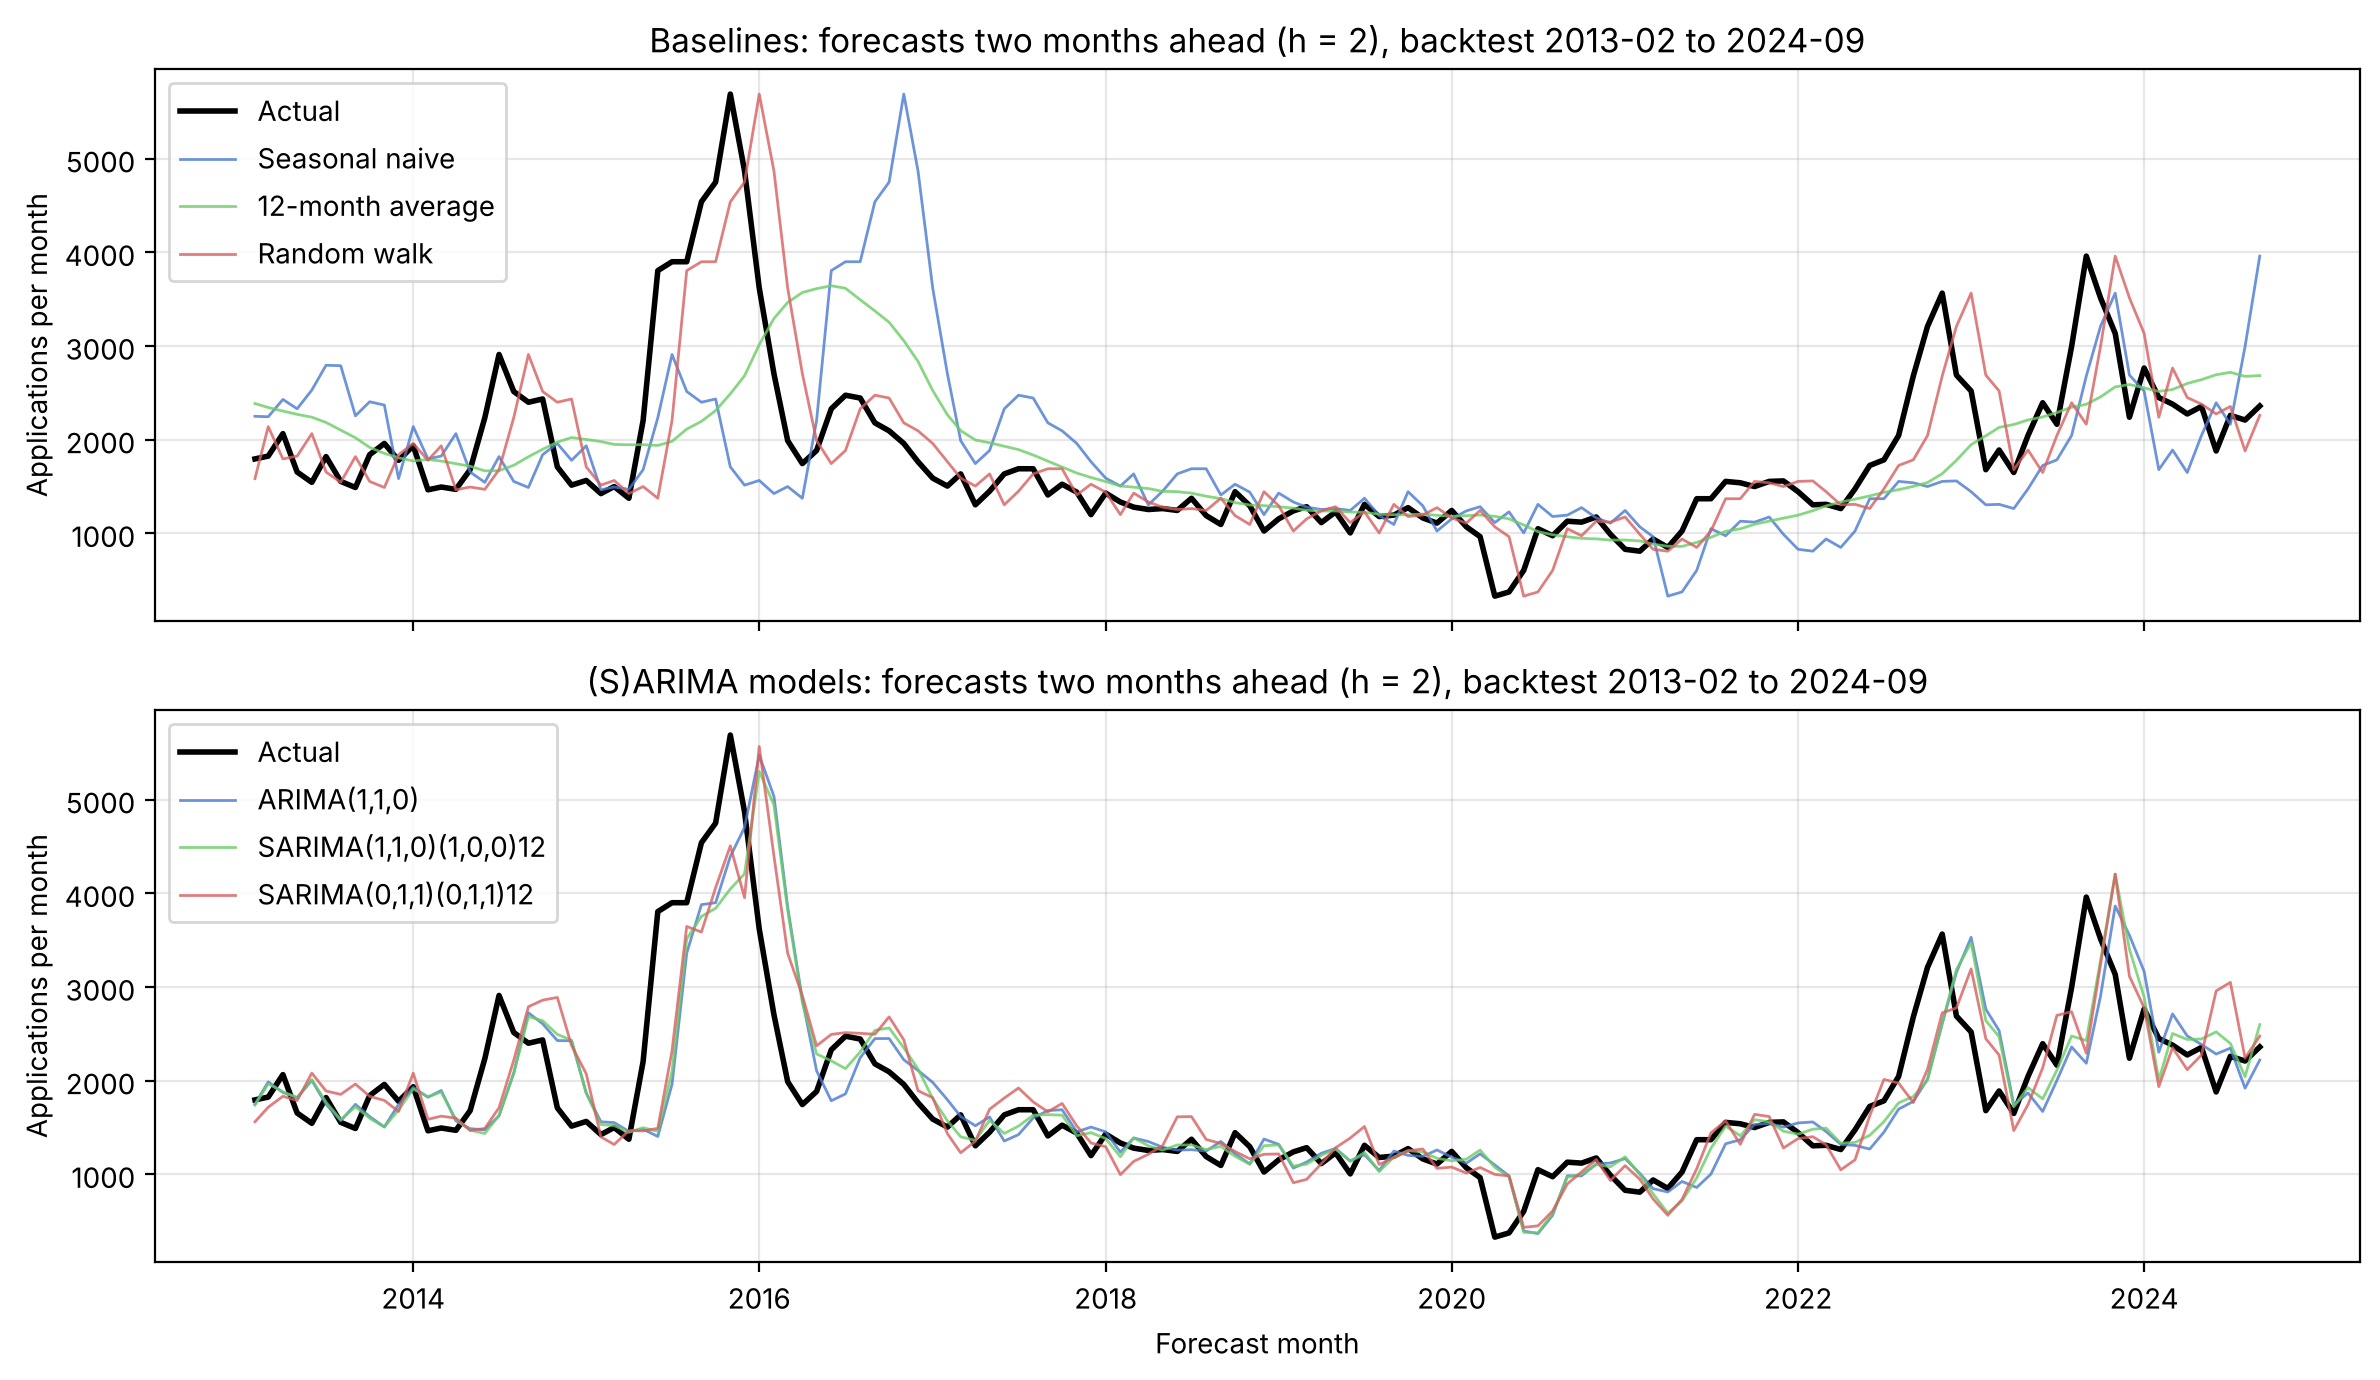

In [9]:
h2 = forecasts[forecasts["h"] == 2]
actual = h2[h2["model"] == "Seasonal naive"].set_index("month")["actual"]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
groups = [["Seasonal naive", "12-month average", "Random walk"],
          ["ARIMA(1,1,0)", "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12"]]
titles = ["Baselines", "(S)ARIMA models"]

for ax, names, title in zip(axes, groups, titles):
    ax.plot(actual.index, actual, color="black", linewidth=2, label="Actual")
    for name in names:
        one = h2[h2["model"] == name].set_index("month")["forecast"]
        ax.plot(one.index, one, linewidth=1, alpha=0.8, label=name)
    ax.set_title(f"{title}: forecasts two months ahead (h = 2), backtest 2013-02 to 2024-09")
    ax.set_ylabel("Applications per month")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
axes[1].set_xlabel("Forecast month")
plt.tight_layout()
plt.savefig("../output/figures/02_backtest_forecasts_h2.png")
plt.show()

In the plot, the seasonal naive (top, blue) repeats the year before: the 2015 peak comes back as a forecast peak of more than 5,000 at the end of 2016, when the actual numbers were much lower, and the drop of spring 2020 comes back in 2021. The 12-month average (top, green) is smooth and reacts slowly: its highest point comes in 2016, months after the actual peak of late 2015. The random walk (top, red) is the actual curve shifted two months to the right: it follows every swing, but always two months late. The three (S)ARIMA models (bottom) follow the level much better than the two slow rules but, as section 7 showed, they stay close to the random walk: their peaks come about two months after the actual peaks of late 2015, 2022 and 2023, and no model foresaw the sudden drop of spring 2020.

So the (S)ARIMA models react late to sudden changes, because they only use the past of the series. This delay is the reason for the next two notebooks: regressions with inputs we choose (`02b_estimate_regression.ipynb`) and the route indicator (`02c_estimate_indicator.ipynb`), which could signal a change earlier.

## 9. Save the forecasts

We save all forecasts, so that `03_evaluate.ipynb` can compare these six models with the regressions of `02b` and `02c` on exactly the same months.

In [10]:
forecasts.to_csv("../data/processed/backtest_forecasts.csv", index=False)
print("Saved", forecasts.shape[0], "forecasts with the columns", list(forecasts.columns))

Saved 2520 forecasts with the columns ['model', 'origin', 'month', 'h', 'forecast_log', 'actual_log', 'forecast', 'actual']


## Summary

In this notebook, we first fixed when a forecast is made: around the 15th of month $m$, when SEM publishes month $m-1$, the forecast origin. From there we forecast $h = 1$, 2 and 3 months ahead; our main horizon is $h = 2$, the first full month a planner can still prepare for. We then ran an honest backtest with an expanding window and 141 origins, from December 2012 to August 2024. Every model is refitted at each origin on the months known then, no forecast falls into the test period, and the checks in section 6 confirm this.

We compared the first two steps of our approach: three simple rules (the seasonal naive, the 12-month average and the random walk, added after the test) and three (S)ARIMA models suggested by the ACF and the ADF test, all forecasting the log of applications. The (S)ARIMA models follow the level much better than the two slow rules, but at $h = 2$ they stay close to the random walk: past monthly changes say little about the next ones, so they stay near the last known month and are about two months late at turning points.

The next notebooks keep the same backtest: regressions with inputs we choose in `02b`, and the same regressions with the route indicator in `02c`. The 2,520 forecasts are saved in `../data/processed/backtest_forecasts.csv` and evaluated in `03_evaluate.ipynb`, together with those of `02b` and `02c`.

*Not seen in class (marked above):* choosing the orders of (S)ARIMA models with the ACF and the ADF test.